# Wine quality

Inspect the UCI Wine Quality dataset (id 186). Each row is one wine. The features are physicochemical lab measurements, and `quality` is a sensory score from 0 to 10. The file joins the red and white Vinho Verde samples; `color` records which one.

A logistic regression on the 11 lab measurements is the baseline for that score.

A decision tree, a random forest, and gradient boosting are then fit on the same wines, with `color` encoded.

Red and white are then modeled separately. The target is three groups: poor (scores 3–4), ordinary (5–6), and good (7–9). The forest for each color is tuned on the training wines, including the cut between ordinary and good.



## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.


In [1]:
import ssl

if ssl.create_default_context.__name__ != "_create_default_context_windows_store":
    _create_default_context = ssl.create_default_context

    def _create_default_context_windows_store(*args, **kwargs):
        '''Use the OS trust store, which includes the Avast scanning root.'''
        return _create_default_context()

    ssl.create_default_context = _create_default_context_windows_store


## Load the dataset


In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
wine_quality = fetch_ucirepo(id=186)

# data (as pandas dataframes)
X = wine_quality.data.features
y = wine_quality.data.targets

# metadata
print(wine_quality.metadata)

# variable information
print(wine_quality.variables)

df = X.copy()
df["quality"] = y.iloc[:, 0]
df["color"] = wine_quality.data.original["color"]


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

## Inspect the data

`df` is the 11 physicochemical features, the sensory score `quality`, and `color` (red or white). There are no missing values. The UCI metadata field `num_instances` is 4,898, the white-wine count. The downloaded file is both colors: 1,599 red and 4,898 white, 6,497 rows.


In [3]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


   fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free_sulfur_dioxide  total_sulfur_dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality color  
0      9.4        5   red  
1      9.8        5   red  
2 

## Investigate the target

`quality` is an integer score. Most wines are 5 or 6. Scores 3, 4, 8, and 9 are rare, and this file has no 0, 1, 2, or 10. White wines outnumber red wines about three to one.


In [4]:
print(df["quality"].value_counts().sort_index())
print(df["color"].value_counts())
print(df.groupby("color")["quality"].value_counts().sort_index().unstack(fill_value=0))


quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64
color
white    4898
red      1599
Name: count, dtype: int64
quality   3    4     5     6    7    8  9
color                                    
red      10   53   681   638  199   18  0
white    20  163  1457  2198  880  175  5


## Visualise relationships

The pairplot crosses all 11 lab measurements. Each point is one wine, and each quality score has its own color. Higher scores sit toward higher alcohol and lower density.


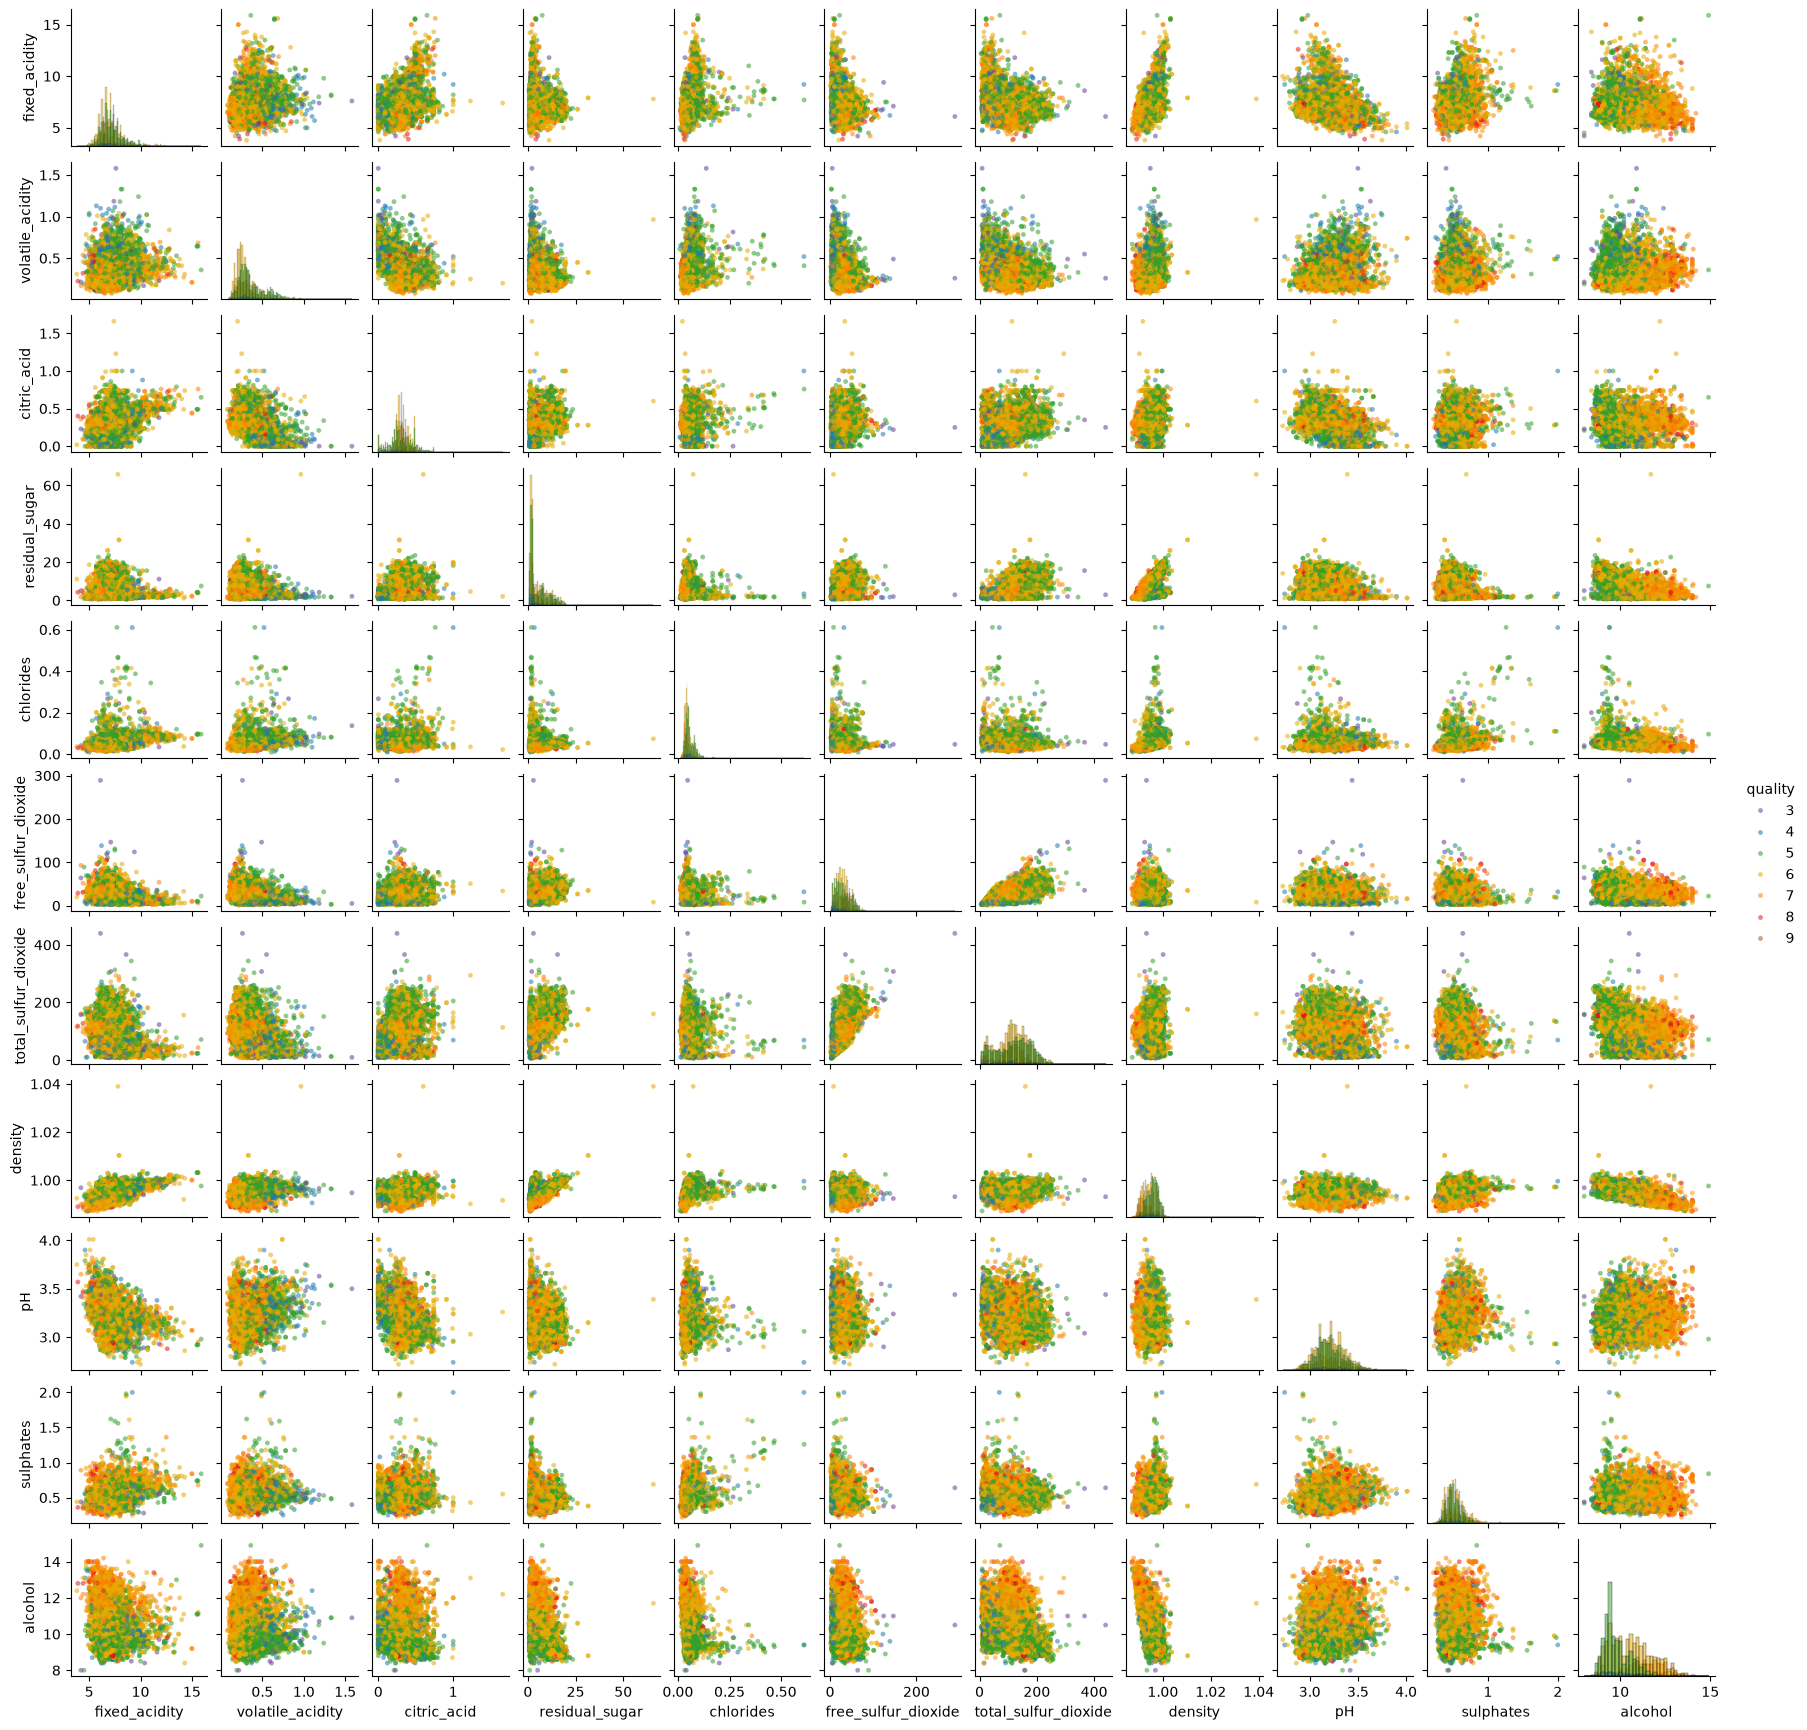

In [5]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df.drop(columns="color").copy()
plot_df["quality"] = plot_df["quality"].astype(str)
quality_order = [str(score) for score in sorted(df["quality"].unique())]

sns.pairplot(
    plot_df,
    hue="quality",
    hue_order=quality_order,
    diag_kind="hist",
    height=1.6,
    palette={
        "3": "#6A3D9A",
        "4": "#1F78B4",
        "5": "#33A02C",
        "6": "#E6AB02",
        "7": "#FF7F00",
        "8": "#E31A1C",
        "9": "#A65628",
    },
    plot_kws={"s": 12, "alpha": 0.55, "linewidth": 0},
)
plt.show()


## Train and test split

Hold out 20% of the wines. Stratify on `quality` so each score keeps the same share in both sets. Score 9 has only 5 wines, so the held-out set contains one of them.


In [6]:
from sklearn.model_selection import train_test_split

features = df.drop(columns=["quality", "color"])
labels = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


Train: 5197 Test: 1300
quality
3      24
4     173
5    1710
6    2269
7     863
8     154
9       4
Name: count, dtype: int64
quality
3      6
4     43
5    428
6    567
7    216
8     39
9      1
Name: count, dtype: int64


## Logistic regression

The 11 lab measurements are the inputs. A `StandardScaler` comes first: density sits near 1, while sulfur dioxide is measured in the tens and hundreds, and logistic regression is sensitive to that scale. There are no missing values.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
model.fit(X_train, y_train)
print("Fitted logistic regression")


Fitted logistic regression


## Evaluate on the held-out set

Accuracy is compared with always predicting the most common training score. The confusion matrix shows which scores the model actually chooses.


Accuracy: 0.535
Always predict 6: 0.436
Within one grade: 0.952
Always predict 6, within one grade: 0.932
Mean absolute error: 0.521

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       1.00      0.02      0.05        43
           5       0.58      0.54      0.56       428
           6       0.51      0.71      0.60       567
           7       0.52      0.28      0.37       216
           8       0.00      0.00      0.00        39
           9       0.00      0.00      0.00         1

    accuracy                           0.53      1300
   macro avg       0.37      0.22      0.22      1300
weighted avg       0.53      0.53      0.51      1300



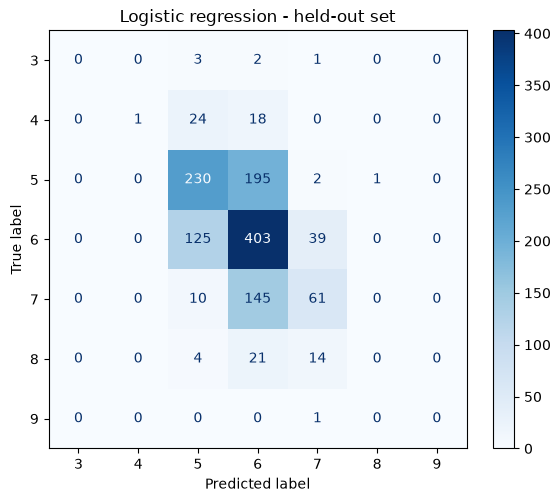

In [8]:
import numpy as np

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_pred = model.predict(X_test)
held_out = y_test.to_numpy()
predicted = np.asarray(y_pred)
common_score = int(y_train.mode().iloc[0])
majority = np.full(len(held_out), common_score)

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_score}: {accuracy_score(held_out, majority):.3f}")
print(f"Within one grade: {np.mean(np.abs(held_out - predicted) <= 1):.3f}")
print(
    f"Always predict {common_score}, within one grade: "
    f"{np.mean(np.abs(held_out - majority) <= 1):.3f}"
)
print(f"Mean absolute error: {np.mean(np.abs(held_out - predicted)):.3f}")
print()
print(classification_report(held_out, predicted, zero_division=0))

labels_order = list(model.named_steps["classifier"].classes_)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    labels=labels_order,
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title("Logistic regression - held-out set")
fig.tight_layout()
plt.show()


## The baseline needs improvement

On the 1,300 held-out wines, accuracy is 0.535. Always predicting 6, the most common training score, scores 0.436. The gain is real, and it comes from sorting ordinary wines into 5, 6, and 7.

The tails are missed. This model never predicts 3, 8, or 9 on the held-out wines, and it predicts 4 once. Recall is 0 for scores 3, 8, and 9. Macro-averaged F1 is 0.22.

Within one grade looks strong, at 0.952, and always predicting 6 is already within one grade for 0.932 of these wines. Scores 5, 6, and 7 are 1,211 of the 1,300 rows. Mean absolute error is 0.52, about half a point, because a mistake is usually a neighboring score.

The linear baseline is a weak description of the rare scores.


## Decision tree, random forest, and gradient boosting

`color` is one-hot encoded. These three models split on the measurements, so the lab values are left unscaled. `random_state=42` keeps them reproducible. The forest uses 100 trees. Gradient boosting is `HistGradientBoostingClassifier`.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

numeric_features = list(features.columns)
categorical_features = ["color"]


def make_preprocess():
    categorical = Pipeline(
        [
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            )
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", "passthrough", numeric_features),
            ("categorical", categorical, categorical_features),
        ]
    )


train_rows = df.loc[X_train.index, numeric_features + categorical_features]
test_rows = df.loc[X_test.index, numeric_features + categorical_features]

models = {
    "Decision tree": Pipeline(
        [
            ("preprocess", make_preprocess()),
            ("classifier", DecisionTreeClassifier(random_state=42)),
        ]
    ),
    "Random forest": Pipeline(
        [
            ("preprocess", make_preprocess()),
            ("classifier", RandomForestClassifier(n_estimators=100, random_state=42)),
        ]
    ),
    "Gradient boosting": Pipeline(
        [
            ("preprocess", make_preprocess()),
            ("classifier", HistGradientBoostingClassifier(random_state=42)),
        ]
    ),
}

for name, candidate in models.items():
    candidate.fit(train_rows, y_train)
    print(f"Fitted {name}")


Fitted Decision tree


Fitted Random forest


Fitted Gradient boosting


## Compare on the held-out set

The same 1,300 wines are scored again. For each model the code calculates accuracy, the share of predictions within one grade, and mean absolute error. Within one grade means the absolute difference between the predicted score and the true score is at most 1.


model                    accuracy   within one grade      mae
Decision tree               0.588              0.912    0.511
Random forest               0.684              0.971    0.350
Gradient boosting           0.612              0.927    0.483

Decision tree
Accuracy: 0.588
Within one grade: 0.912
Mean absolute error: 0.511

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.18      0.14      0.16        43
           5       0.67      0.63      0.65       428
           6       0.63      0.62      0.62       567
           7       0.49      0.56      0.52       216
           8       0.33      0.44      0.37        39
           9       0.00      0.00      0.00         1

    accuracy                           0.59      1300
   macro avg       0.33      0.34      0.33      1300
weighted avg       0.59      0.59      0.59      1300



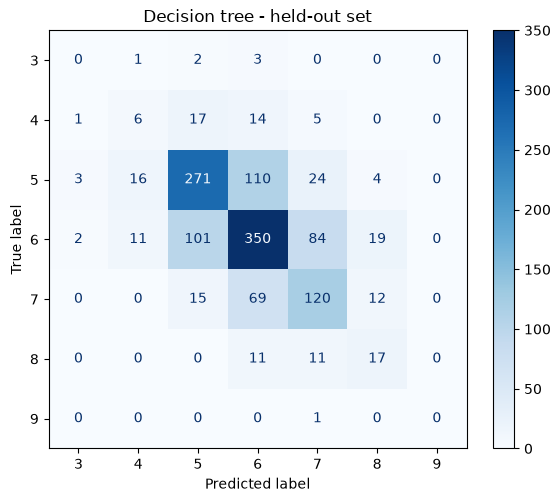


Random forest
Accuracy: 0.684
Within one grade: 0.971
Mean absolute error: 0.350

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.70      0.16      0.26        43
           5       0.73      0.70      0.71       428
           6       0.66      0.78      0.72       567
           7       0.66      0.57      0.61       216
           8       0.93      0.36      0.52        39
           9       0.00      0.00      0.00         1

    accuracy                           0.68      1300
   macro avg       0.52      0.37      0.40      1300
weighted avg       0.69      0.68      0.67      1300



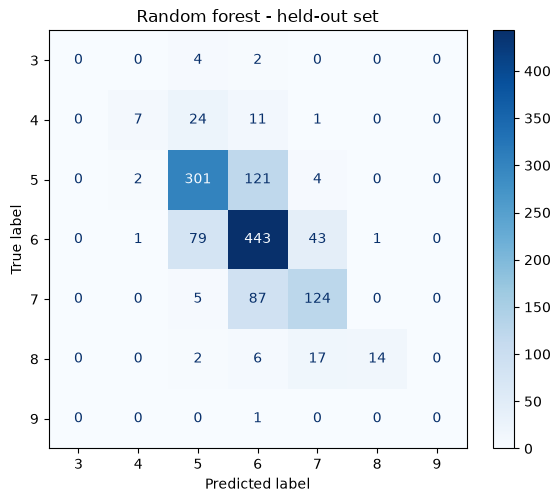


Gradient boosting
Accuracy: 0.612
Within one grade: 0.927
Mean absolute error: 0.483

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.23      0.23      0.23        43
           5       0.70      0.61      0.65       428
           6       0.63      0.69      0.66       567
           7       0.58      0.56      0.57       216
           8       0.42      0.33      0.37        39
           9       0.00      0.00      0.00         1

    accuracy                           0.61      1300
   macro avg       0.37      0.35      0.36      1300
weighted avg       0.62      0.61      0.62      1300



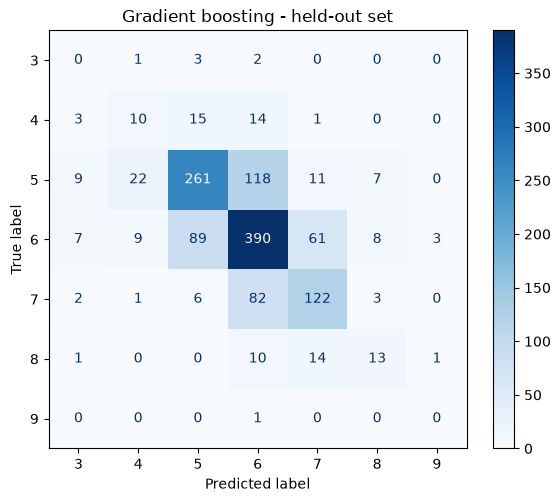

In [10]:
def score_predictions(truth, pred):
    truth = np.asarray(truth)
    pred = np.asarray(pred)
    return {
        "accuracy": accuracy_score(truth, pred),
        "within one grade": float(np.mean(np.abs(truth - pred) <= 1)),
        "mean absolute error": float(np.mean(np.abs(truth - pred))),
    }


print(f"{'model':<22} {'accuracy':>10} {'within one grade':>18} {'mae':>8}")
fitted = {}
for name, candidate in models.items():
    pred = candidate.predict(test_rows)
    scores = score_predictions(y_test, pred)
    fitted[name] = pred
    print(
        f"{name:<22} {scores['accuracy']:10.3f} "
        f"{scores['within one grade']:18.3f} {scores['mean absolute error']:8.3f}"
    )

for name, pred in fitted.items():
    scores = score_predictions(y_test, pred)
    print()
    print(name)
    print(f"Accuracy: {scores['accuracy']:.3f}")
    print(f"Within one grade: {scores['within one grade']:.3f}")
    print(f"Mean absolute error: {scores['mean absolute error']:.3f}")
    print()
    print(classification_report(y_test, pred, zero_division=0))
    labels_order = list(models[name].named_steps["classifier"].classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=labels_order,
        ax=ax,
        cmap="Blues",
        xticks_rotation=0,
    )
    ax.set_title(f"{name} - held-out set")
    fig.tight_layout()
    plt.show()


## Who performs better

Random forest is ahead on all three calculated scores: accuracy 0.684, within one grade 0.971, and mean absolute error 0.350.

Gradient boosting is next on accuracy, at 0.612. Its within-one-grade rate is 0.927 and its mean absolute error is 0.483. It calls scores 4 and 8, with recall 0.23 and 0.33.

The decision tree reaches accuracy 0.588. Its within-one-grade rate is 0.912, the lowest of the three, and its mean absolute error is 0.511.

Score 9 is absent from every prediction. Score 3 has recall 0 for all three models. The forest recall is 0.16 for score 4. Score 8 is the tail it catches, with precision 0.93 and recall 0.36.


## Two types of wine

Red and white wines do not share the same chemistry. Volatile acidity, residual sugar, and sulfur dioxide sit in different ranges, so a good red wine is not the same pattern as a good white wine.

The forest below is fit twice: once on the red training wines and once on the white training wines. Each held-out wine is scored by the forest of its own color.


## Poor, ordinary, and good

The score itself stays hard to hit exactly. Scores 3 and 4 become `poor`, scores 5 and 6 become `ordinary`, and scores 7, 8, and 9 become `good`.

Accuracy is compared with always predicting `ordinary`. Within one group uses the order poor, ordinary, good. Always predicting ordinary scores 1 on that calculation, because both other groups sit next to it. The useful comparison is accuracy.


## Tune the forest

The 1,300 held-out wines stay unused while the settings are chosen. For each color, stratified 4-fold cross-validation picks `max_depth` and `min_samples_leaf` by accuracy on the three groups.

A second choice is the cut between `ordinary` and `good`. A wine the forest does not call `poor` is called `good` when the probability of `good` is at least that cut, and `ordinary` otherwise. The cut is chosen from the training out-of-fold predictions, as the value from 0.30 to 0.60 that maximizes accuracy.

The three changes are applied together in the next cell. One confusion matrix is drawn, for those final predictions.


Train {'poor': 197, 'ordinary': 3979, 'good': 1021}
Test {'poor': 49, 'ordinary': 995, 'good': 256}


red train {'poor': 50, 'ordinary': 1075, 'good': 168}


red chosen {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1} cv accuracy 0.865 good cut 0.4
white train {'poor': 147, 'ordinary': 2904, 'good': 853}


white chosen {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1} cv accuracy 0.832 good cut 0.45
model                    accuracy   within one group
----------------------------------------------------
Always ordinary             0.765              1.000
One forest                  0.854              0.999
Separate forests            0.855              0.999

Separate forests
              precision    recall  f1-score   support

        poor       0.71      0.10      0.18        49
    ordinary       0.89      0.93      0.91       995
        good       0.73      0.71      0.72       256

    accuracy                           0.86      1300
   macro avg       0.78      0.58      0.60      1300
weighted avg       0.85      0.86      0.84      1300



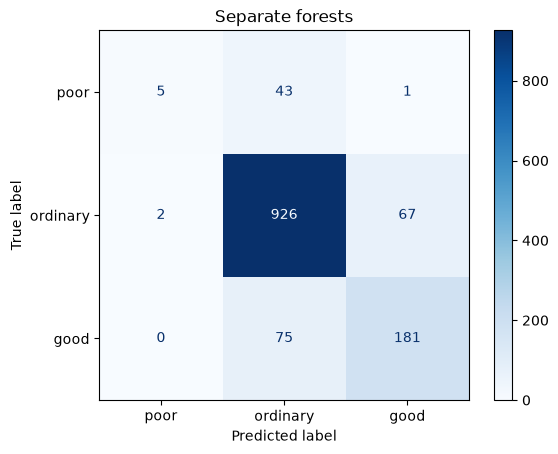

In [11]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict


def quality_group(scores):
    scores = np.asarray(scores)
    groups = np.full(len(scores), "ordinary", dtype=object)
    groups[scores <= 4] = "poor"
    groups[scores >= 7] = "good"
    return groups


group_order = {"poor": 0, "ordinary": 1, "good": 2}
group_labels = ["poor", "ordinary", "good"]


def score_groups(truth, pred):
    truth = np.asarray(truth)
    pred = np.asarray(pred)
    truth_rank = np.array([group_order[value] for value in truth])
    pred_rank = np.array([group_order[value] for value in pred])
    return {
        "accuracy": accuracy_score(truth, pred),
        "within one group": float(np.mean(np.abs(truth_rank - pred_rank) <= 1)),
    }


def predict_with_cut(proba, classes, cut):
    class_list = list(classes)
    good_index = class_list.index("good")
    poor_index = class_list.index("poor")
    ordinary_index = class_list.index("ordinary")
    chosen = []
    for row in proba:
        if row[poor_index] >= row[good_index] and row[poor_index] >= row[ordinary_index]:
            chosen.append("poor")
        elif row[good_index] >= cut:
            chosen.append("good")
        else:
            chosen.append("ordinary")
    return np.array(chosen, dtype=object)


y_train_group = quality_group(y_train)
y_test_group = quality_group(y_test)
print("Train", {name: int(np.sum(y_train_group == name)) for name in group_labels})
print("Test", {name: int(np.sum(y_test_group == name)) for name in group_labels})

pooled = Pipeline([
    ("preprocess", make_preprocess()),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42)),
])
pooled.fit(train_rows, y_train_group)
pooled_pred = pooled.predict(test_rows)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
cuts = np.round(np.arange(0.30, 0.61, 0.05), 2)
final_pred = np.empty(len(y_test_group), dtype=object)

for color in ["red", "white"]:
    train_mask = train_rows["color"].to_numpy() == color
    test_mask = test_rows["color"].to_numpy() == color
    X_color = train_rows.loc[train_mask]
    y_color = y_train_group[train_mask]
    print(color, "train", {name: int(np.sum(y_color == name)) for name in group_labels})

    search = GridSearchCV(
        Pipeline([
            ("preprocess", make_preprocess()),
            ("classifier", RandomForestClassifier(n_estimators=100, random_state=42)),
        ]),
        {
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_leaf": [1, 5, 10],
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_color, y_color)
    classes = search.best_estimator_.named_steps["classifier"].classes_
    oof = cross_val_predict(
        clone(search.best_estimator_),
        X_color,
        y_color,
        cv=cv,
        method="predict_proba",
        n_jobs=-1,
    )
    best_cut = cuts[0]
    best_train_accuracy = -1.0
    for cut in cuts:
        train_accuracy = accuracy_score(y_color, predict_with_cut(oof, classes, cut))
        if train_accuracy > best_train_accuracy:
            best_cut = float(cut)
            best_train_accuracy = train_accuracy
    final_pred[test_mask] = predict_with_cut(
        search.predict_proba(test_rows.loc[test_mask]), classes, best_cut
    )
    print(
        color,
        "chosen",
        search.best_params_,
        "cv accuracy",
        round(float(search.best_score_), 3),
        "good cut",
        best_cut,
    )

rows = [
    ("Always ordinary", score_groups(y_test_group, np.full(len(y_test_group), "ordinary"))),
    ("One forest", score_groups(y_test_group, pooled_pred)),
    ("Separate forests", score_groups(y_test_group, final_pred)),
]
header = f"{'model':<22} {'accuracy':>10} {'within one group':>18}"
print(header)
print("-" * len(header))
for name, scores in rows:
    print(f"{name:<22} {scores['accuracy']:>10.3f} {scores['within one group']:>18.3f}")

print("\nSeparate forests")
print(classification_report(y_test_group, final_pred, labels=group_labels, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test_group,
    final_pred,
    labels=group_labels,
    cmap="Blues",
)
plt.title("Separate forests")
plt.show()


## What the three changes do

Separate forests, with the depth and leaf chosen on the training wines and a cut on the probability of `good`, score 0.855 accuracy and 0.999 within one group on the 1,300 held-out wines. Always predicting `ordinary` scores 0.765 and 1.000. One forest on all wines, with no extra cut, scores 0.854 and 0.999.

The red forest keeps unlimited depth and one sample per leaf. Its cross-validated accuracy is 0.865, and it calls a wine `good` when that probability is at least 0.40. The white forest uses depth 20 and one sample per leaf. Its cross-validated accuracy is 0.832, and its cut is 0.45.

On the held-out wines, `poor` precision is 0.71 and recall is 0.10. `ordinary` precision is 0.89 and recall is 0.93. `good` precision is 0.73 and recall is 0.71. Accuracy barely moves past the single forest. The extra good wines that the lower cut recovers are about as many as the ordinary wines it newly calls good.


## A log on the long tails

`residual_sugar`, `free_sulfur_dioxide`, and `total_sulfur_dioxide` sit near zero for many wines and then run far to the right. This section takes the log of one plus each of those three, then the same scaler and the same logistic regression. The other eight measurements stay as recorded. `color` stays out of this fit, as it does in the first logistic regression.

Accuracy: 0.548
Always predict 6: 0.436
Within one grade: 0.960
Always predict 6, within one grade: 0.932
Mean absolute error: 0.498

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.60      0.07      0.12        43
           5       0.60      0.55      0.57       428
           6       0.52      0.72      0.61       567
           7       0.54      0.30      0.38       216
           8       0.00      0.00      0.00        39
           9       0.00      0.00      0.00         1

    accuracy                           0.55      1300
   macro avg       0.32      0.23      0.24      1300
weighted avg       0.54      0.55      0.52      1300



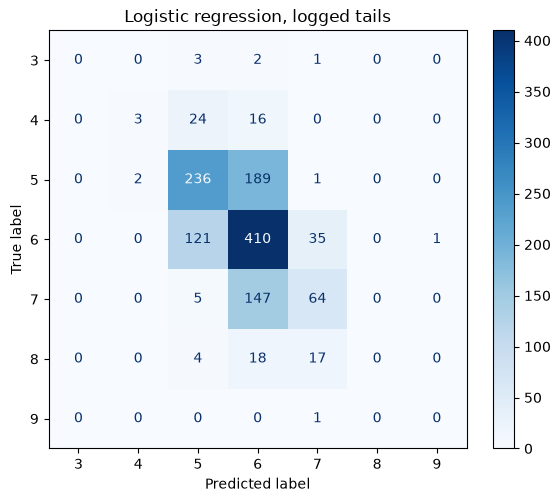

In [12]:
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

skewed = ["residual_sugar", "free_sulfur_dioxide", "total_sulfur_dioxide"]
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log[skewed] = np.log1p(X_train_log[skewed])
X_test_log[skewed] = np.log1p(X_test_log[skewed])

logged_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
logged_model.fit(X_train_log, y_train)
logged_pred = logged_model.predict(X_test_log)
held_out = y_test.to_numpy()
predicted = np.asarray(logged_pred)
common_score = int(y_train.mode().iloc[0])
majority = np.full(len(held_out), common_score)

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_score}: {accuracy_score(held_out, majority):.3f}")
print(f"Within one grade: {np.mean(np.abs(held_out - predicted) <= 1):.3f}")
print(
    f"Always predict {common_score}, within one grade: "
    f"{np.mean(np.abs(held_out - majority) <= 1):.3f}"
)
print(f"Mean absolute error: {np.mean(np.abs(held_out - predicted)):.3f}")
print()
print(classification_report(held_out, predicted, zero_division=0))

labels_order = list(logged_model.named_steps["classifier"].classes_)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    labels=labels_order,
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title("Logistic regression, logged tails")
fig.tight_layout()
plt.show()


## Held-out wines after the log

On the 1,300 held-out wines, accuracy is 0.548. The unlogged logistic regression scores 0.535. Always predicting 6 scores 0.436. Within one grade is 0.960, and the unlogged model is at 0.952. Mean absolute error is 0.498, and the unlogged model is at 0.521. Macro-averaged F1 is 0.24, and the unlogged model is at 0.22.

Scores 3 and 8 are still missing from the predictions. One held-out wine is called 9. The forest on the exact score stays ahead, at accuracy 0.684.

## Conclusion

The file has 6,497 wines, 11 lab measurements, and a sensory score from 3 to 9. Red and white are recorded in `color`.

Logistic regression on the exact score reaches accuracy 0.535 on the 1,300 held-out wines. Always predicting 6 scores 0.436. A decision tree, a random forest, and gradient boosting follow, with `color` encoded. The forest is ahead of those three: accuracy 0.684, within one grade 0.971, and mean absolute error 0.350.

The score is then grouped into poor (3–4), ordinary (5–6), and good (7–9). A forest is fit separately for red and white, and its depth, leaf size, and cut for `good` are chosen on the training wines. On the same held-out wines that model scores 0.855 accuracy. Always predicting ordinary scores 0.765.

The same logistic regression is fit again after a log of `residual_sugar`, `free_sulfur_dioxide`, and `total_sulfur_dioxide`. Held-out accuracy is 0.548, within one grade is 0.960, and mean absolute error is 0.498. The forest on the exact score stays ahead, at accuracy 0.684.
